In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
path = "../data/online_retail_II.xlsx"
df1 = pd.read_excel(path, sheet_name="Year 2009-2010")
df2 = pd.read_excel(path, sheet_name="Year 2010-2011")
df = pd.concat([df1, df2], ignore_index=True)
print("Rows and columns:", df.shape)

KeyboardInterrupt: 

In [ ]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

In [ ]:
# Check for missing values
df.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [ ]:
# Show rows with missing values
df[df.isna().any(axis=1)].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,NaN,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,NaN,United Kingdom


In [ ]:
# Check for duplicates
df.duplicated().sum()


np.int64(34335)

In [ ]:
# Show duplicate rows
df[df.duplicated(keep=False)].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [ ]:
# Show summary statistics for Quantity and Price columns
df[["Quantity", "Price"]].describe().round(2)

,Quantity,Price
count,1067371.00,1067371.00
mean,9.94,4.65
std,172.71,123.55
min,-80995.00,-53594.36
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,80995.00,38970.00


Quantity: The median is 3, while the mean is around 9.94. This suggests that some transactions have much larger quantities than others.

Price: The median price is 2.10, while the mean is 4.65.

Negative values: Both Quantity and Price contain negative values. These may be related to returns, cancellations, or data errors.

Extreme values: The maximum values are much higher than the median, so further investigation is needed.

In [ ]:
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())

Quantity <= 0: 22950


In [ ]:
print("Price <= 0:", (df["Price"] <= 0).sum())

Price <= 0: 6207


In [ ]:
clean = df.copy()

In [ ]:
clean = clean.drop_duplicates()
clean = clean.dropna(subset=["Customer ID"])

In [ ]:
clean = clean[(clean["Quantity"] > 0) & (clean["Price"] > 0)].copy()

In [ ]:
clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 779425 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      779425 non-null  object        
 1   StockCode    779425 non-null  object        
 2   Description  779425 non-null  object        
 3   Quantity     779425 non-null  int64         
 4   InvoiceDate  779425 non-null  datetime64[ns]
 5   Price        779425 non-null  float64       
 6   Customer ID  779425 non-null  float64       
 7   Country      779425 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 53.5+ MB


In [ ]:
# Create a new column "Revenue" by multiplying "Quantity" and "Price"
clean["Revenue"] = clean["Quantity"] * clean["Price"]

In [ ]:
# Create a new column "Month" by extracting the month from "InvoiceDate"
clean["Month"] = clean["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

In [ ]:
clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009-12-01
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12-01
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12-01
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,2009-12-01
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12-01


In [43]:
# Group the data by "Month" and calculate the total revenue for each month
monthly_sales = clean.groupby("Month", as_index=False)["Revenue"].sum()
monthly_sales.head()

,Month,Revenue
0,2009-12-01,683504.010
1,2010-01-01,555802.672
2,2010-02-01,504558.956
3,2010-03-01,696978.471
4,2010-04-01,591982.002


In [45]:
monthly_sales["Revenue_Millions"] = monthly_sales["Revenue"] / 1_000_000
monthly_sales.head()

,Month,Revenue,Revenue_Millions
0,2009-12-01,683504.010,0.683504
1,2010-01-01,555802.672,0.555803
2,2010-02-01,504558.956,0.504559
3,2010-03-01,696978.471,0.696978
4,2010-04-01,591982.002,0.591982


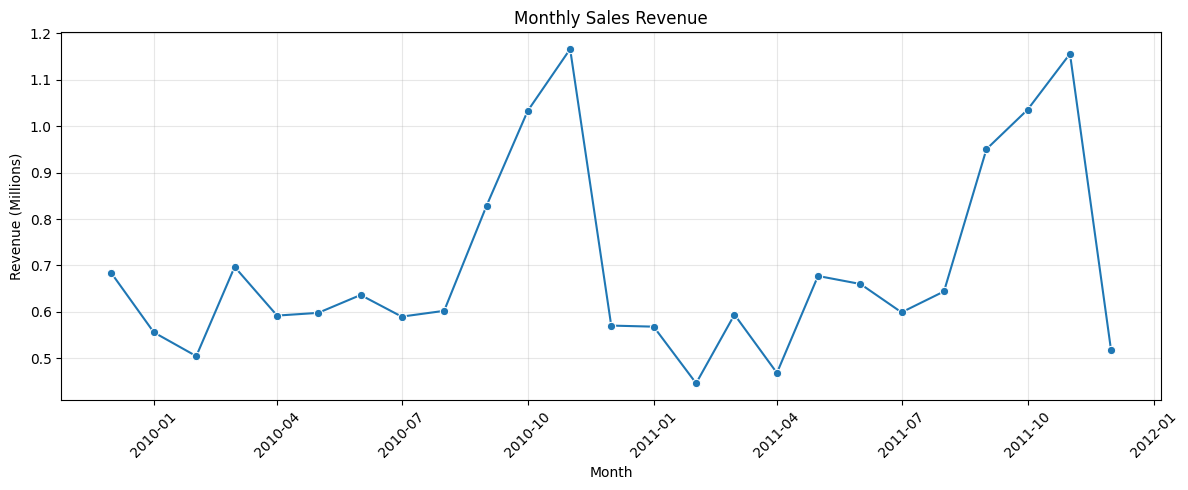

In [47]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Revenue_Millions",
    marker="o"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (Millions)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Insights – Monthly Sales Revenue

Seasonal pattern: Revenue increases strongly from September to November in both years, with the highest sales around November.
Lower sales: Revenue is generally lower in the first months of the year.
Business value: The company could use these patterns to plan inventory and marketing campaigns before the peak sales period.

Note: December 2011 contains only partial month data, so its revenue should not be directly compared with full months. The analysis also excludes returns and cancellations.

In [ ]:
# Create a mapping of StockCode to Description
#product_mapping = df[['StockCode', 'Description']].drop_duplicates(subset='StockCode')
#product_mapping

,StockCode,Description
0,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS
1,79323P,PINK CHERRY LIGHTS
2,79323W,WHITE CHERRY LIGHTS
3,22041,"RECORD FRAME 7"" SINGLE SIZE"
4,21232,STRAWBERRY CERAMIC TRINKET BOX
...,...,...
1029063,23562,SET OF 6 RIBBONS PERFECTLY PRETTY
1029565,23561,SET OF 6 RIBBONS PARTY
1033328,23609,SET 10 CARDS SNOWY ROBIN 17099
1038049,23617,SET 10 CARDS SWIRLY XMAS TREE 17104


In [57]:
top_products = (
    clean.groupby("StockCode")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

StockCode
22423     277656.25
85123A    247203.36
23843     168469.60
85099B    167920.64
M         151777.67
POST      124648.04
84879     124351.86
47566     103283.38
23166      81416.73
22086      76598.18
Name: Revenue, dtype: float64

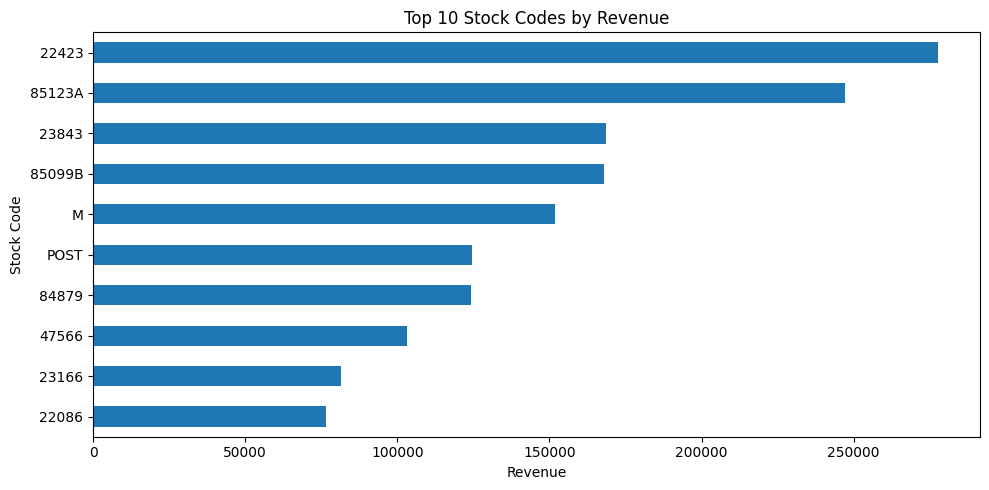

In [58]:
plt.figure(figsize=(10, 5))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Stock Codes by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Stock Code")
plt.tight_layout()
plt.show()